# HVQC — Full Project: Hybrid Variational Quantum Classifier with a Manually Constructed Ansatz
**PneumoniaMNIST · 8 qubits · Qiskit Aer / FakeSherbrooke / (optional) real IBM hardware**

Runs top to bottom in Colab (CPU is enough). Each section maps to a study-guide objective:

| Section | What it does | Study-guide anchor |
|---|---|---|
| 1-2 | Config, data, PCA -> 2x4 -> trainable CNN -> `pi*sigmoid` angle encoding | Obj. 1-2, §3.1 |
| 3 | The manual ansatz ("Converging-Cascade") + the library ansätze used as comparison | Obj. 3, §3.2, §11 |
| 4 | Fast exact simulator + proof it equals Aer and the parameter-shift rule | §3.4 |
| 5 | Ansatz verification: light cone, dead parameters, barren-plateau gradient variance | §3.6, Q10 |
| 6 | Hybrid training (Adam, CNN + ansatz jointly) | Obj. 4 |
| 7 | **Real parameter-shift training on Aer** (the headline run) and cross-check against section 4 | §3.4 |
| 8 | Multi-seed experiments: ansatz comparison, entanglement ablation, depth 1/2/3, PCA vs CNN | §8, Q4, Q7 |
| 9 | Classical baselines: SVM / shallow NN on same features, raw pixels, classical twin | Obj. 5, Q3 |
| 10 | NISQ: shots sensitivity, FakeSherbrooke noise, transpiled cost | §3.5, Q9 |
| 11 | Optional real IBM hardware run | Week 4, Q5 |
| 12 | Benchmark summary, figures, auto-generated results text | Obj. 5, §8 |

**Why a "fast exact simulator" next to Aer?** Parameter-shift needs 2 circuit runs per parameter per sample. That is fine once (section 7), but multi-seed sweeps would take hours. For an ideal (noise-free) circuit the shift rule returns *exactly* the analytic gradient, so section 4 proves the equivalence and section 8 uses the fast path. Noise, shots and hardware always go through Qiskit.

## 1. Setup and configuration

In [1]:
!pip install qiskit qiskit-aer qiskit-ibm-runtime medmnist pylatexenc pandas -q

In [2]:
import time, warnings, os
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score

import torch, torch.nn as nn, torch.nn.functional as F

from qiskit import QuantumCircuit, transpile
from qiskit.circuit import ParameterVector
from qiskit.circuit.library import real_amplitudes, efficient_su2
from qiskit.quantum_info import SparsePauliOp
from qiskit_aer import AerSimulator
from qiskit_aer.primitives import EstimatorV2 as AerEstimator
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke

import medmnist
from medmnist import INFO

from google.colab import userdata
IBM_TOKEN=userdata.get('IBM_Token')

N_QUBITS = 8
SHIFT = np.pi / 2

In [3]:
# ------------------------------- CONFIG -------------------------------
QUICK = False            # True = tiny smoke-test settings (minutes); False = the real study

if QUICK:
    SEEDS, N_TRAIN, N_TEST, EPOCHS, LR = [0, 1], 60, 40, 12, 0.01
    N_PS_TRAIN, N_PS_EPOCHS, N_NOISY, SHOTS_LIST = 40, 6, 20, [200, 4000]
else:
    SEEDS, N_TRAIN, N_TEST, EPOCHS, LR = [0, 1, 2, 3, 4], 200, 200, 40, 0.02
    N_PS_TRAIN, N_PS_EPOCHS, N_NOISY, SHOTS_LIST = 60, 12, 40, [100, 500, 1000, 4000, 8000]

SHOTS_NOISY = 4000       # shots for the FakeSherbrooke / hardware runs (Q9)
RUN_HARDWARE = True     # set True only after pasting your IBM token below (Section 11)         # https://quantum.cloud.ibm.com  -> API key
N_HARDWARE = 20          # test images sent to the real QPU (keeps within ~10 free minutes)
print("seeds", SEEDS, "| N_TRAIN", N_TRAIN, "| N_TEST", N_TEST, "| epochs", EPOCHS, "| lr", LR)

seeds [0, 1, 2, 3, 4] | N_TRAIN 200 | N_TEST 200 | epochs 40 | lr 0.02


## 2. Data and classical feature extraction (Objective 1) + angle encoding (Objective 2)
* Class-balanced random subsets of the real MedMNIST train / test splits (test images are never used for fitting anything).
* **PCA is fit on the training subset only**, then reshaped to a 2x4 "image".
* `feature="cnn"`: a trainable CNN maps the 2x4 PCA image to 8 numbers; `pi*sigmoid` squashes them into (0, π) so rotation periodicity cannot alias two different feature values (§3.1).
* `feature="pca"`: the documented ablation (Q4) — no CNN, PCA components rescaled to [0, π] using *training* min/max only.

train (4708, 28, 28) [1214 3494] | test (624, 28, 28) [234 390]
PCA variance captured by 8 components: 0.726


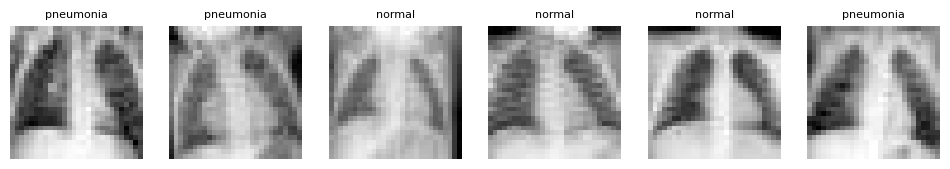

In [4]:
data_flag = "pneumoniamnist"
info = INFO[data_flag]
DataClass = getattr(medmnist, info["python_class"])
train_ds = DataClass(split="train", download=True, size=28)
test_ds  = DataClass(split="test",  download=True, size=28)

def to_arrays(ds):
    X = np.array([np.asarray(ds[i][0]) for i in range(len(ds))], dtype=np.uint8)
    y = np.array([int(np.array(ds[i][1]).squeeze()) for i in range(len(ds))])
    return X, y
X_train_all, y_train_all = to_arrays(train_ds)
X_test_all,  y_test_all  = to_arrays(test_ds)
print("train", X_train_all.shape, np.bincount(y_train_all), "| test", X_test_all.shape, np.bincount(y_test_all))

def balanced_idx(labels, n, rng):
    idx = []
    for c in np.unique(labels):
        pool = np.where(labels == c)[0]
        idx += rng.choice(pool, size=min(n // 2, len(pool)), replace=False).tolist()
    rng.shuffle(idx)
    return np.array(idx)

def make_split(seed):
    rng = np.random.default_rng(1000 + seed)
    tr = balanced_idx(y_train_all, N_TRAIN, rng); te = balanced_idx(y_test_all, N_TEST, rng)
    Xtr = X_train_all[tr].reshape(len(tr), -1) / 255.0; Xte = X_test_all[te].reshape(len(te), -1) / 255.0
    pca = PCA(n_components=N_QUBITS).fit(Xtr)                     # train only
    Ptr, Pte = pca.transform(Xtr), pca.transform(Xte)
    lo, hi = Ptr.min(0), Ptr.max(0)
    resc = lambda P: np.clip(np.pi * (P - lo) / (hi - lo + 1e-12), 0, np.pi)
    t = lambda P: torch.tensor(P, dtype=torch.float32).reshape(-1, 1, 2, 4)
    return dict(seed=seed, ytr=y_train_all[tr], yte=y_test_all[te], pix_tr=Xtr, pix_te=Xte,
                pca_tr=Ptr, pca_te=Pte, img_tr=t(Ptr), img_te=t(Pte),
                ang_tr=torch.tensor(resc(Ptr)), ang_te=torch.tensor(resc(Pte)), evr=pca.explained_variance_ratio_)

split0 = make_split(0)
print("PCA variance captured by 8 components:", round(split0["evr"].sum(), 3))
fig, ax = plt.subplots(1, 6, figsize=(12, 2.2))
for a, i in zip(ax, range(6)):
    a.imshow(split0["pix_tr"][i].reshape(28, 28), cmap="gray"); a.set_title(info["label"][str(split0["ytr"][i])], fontsize=8); a.axis("off")
plt.show()

In [5]:
class FeatureCNN(nn.Module):
    def __init__(self, n_out=N_QUBITS):
        super().__init__()
        self.conv1 = nn.Conv2d(1, 8, 2, padding=1); self.conv2 = nn.Conv2d(8, 16, 2, padding=1)
        self.bn1 = nn.BatchNorm2d(8); self.bn2 = nn.BatchNorm2d(16)
        self.fc1 = nn.Linear(16 * 4 * 6, 64); self.fc2 = nn.Linear(64, n_out); self.drop = nn.Dropout(0.1)
    def forward(self, x):
        x = torch.relu(self.bn1(self.conv1(x))); x = torch.relu(self.bn2(self.conv2(x)))
        return self.fc2(self.drop(torch.relu(self.fc1(x.flatten(1)))))
print("CNN trainable parameters:", sum(p.numel() for p in FeatureCNN().parameters()))

CNN trainable parameters: 25776


## 3. The ansatz (Objective 3)
### The manual "Converging-Cascade" ansatz
```
 q0 ─RY(x0)─RY(θ)─■───────────────────────────────────────────
 q1 ─RY(x1)─RY(θ)─X─RY(θ)─■────────────────────────────────────
 q2 ─RY(x2)─RY(θ)─────────X─RY(θ)─■─────────────────────────────
 q3 ─RY(x3)─RY(θ)─────────────────X─RY(θ)─■─────────────────────
                                           │ merge
 q4 ─RY(x4)─RY(θ)─────────────────X─RY(θ)─X─RX(θ)─RY(θ)─ <Z>  ◄── the single readout qubit
 q5 ─RY(x5)─RY(θ)─────────X─RY(θ)─■─────────────────────────────
 q6 ─RY(x6)─RY(θ)─X─RY(θ)─■────────────────────────────────────
 q7 ─RY(x7)─RY(θ)─■───────────────────────────────────────────
```
(schematic — the exact circuit is drawn below.) One block = **16 parameters, 7 CNOTs**.

**Why each piece is there**
1. **A single, explicit readout qubit (q4)**, and every encoded feature is inside its light cone (verified in §5). The earlier notebooks' `"Z"+"I"*7` actually read q7 (Qiskit is little-endian).
2. **Two cascades converging on the middle**: 7 CNOTs is the minimum that connects 8 qubits (n-1); two half-chains plus a merge halve the two-qubit depth versus one long chain — vital under NISQ noise (§3.5).
3. **Nearest-neighbour CNOTs only** -> no SWAPs on line / heavy-hex hardware.
4. **Trainable gates are single-qubit rotations used once each** -> the π/2 parameter-shift rule is *exact*.
5. **RY (not RZ) first**: the data are encoded with RY, so the state is real. A leading RZ on a pure CNOT-control qubit commutes through and is a *dead* parameter (found numerically). RY after the CNOT acts on the target, where it does not commute, so every parameter is alive.
6. **RY after each CNOT makes the fixed Clifford entangler tunable** — a learnable mix of two features, the quantum analogue of a pooling weight (tree / QCNN-style circuit; shallow + local observable = barren-plateau friendly).
7. **Final RX -> RY on the readout qubit** = a free measurement axis (two angles cover the Bloch sphere).
8. **Entanglement is what makes it quantum** (§3.2): the product-state control in §8 uses the same single-qubit rotations *without* CNOTs.

**Comparison ansätze** (same encoding, same readout rule as the earlier notebooks): `real_amplitudes` (reps=2, linear, 24 params) and `efficient_su2` (reps=2, linear, 48 params), both read out on q7; plus the **product-state control** (no CNOTs, 16 params, mean of `<Z>` over all qubits so it can see every feature).

design                     params  CNOTs    param-shift runs / sample / step
manual (1 block)               16      7                                  48
manual (2 blocks)              32     14                                  80
manual (3 blocks)              48     21                                 112
real_amplitudes r2             24     14                                  64
efficient_su2 r2               48     14                                 112
product-state (no CNOT)        16      0                                  48


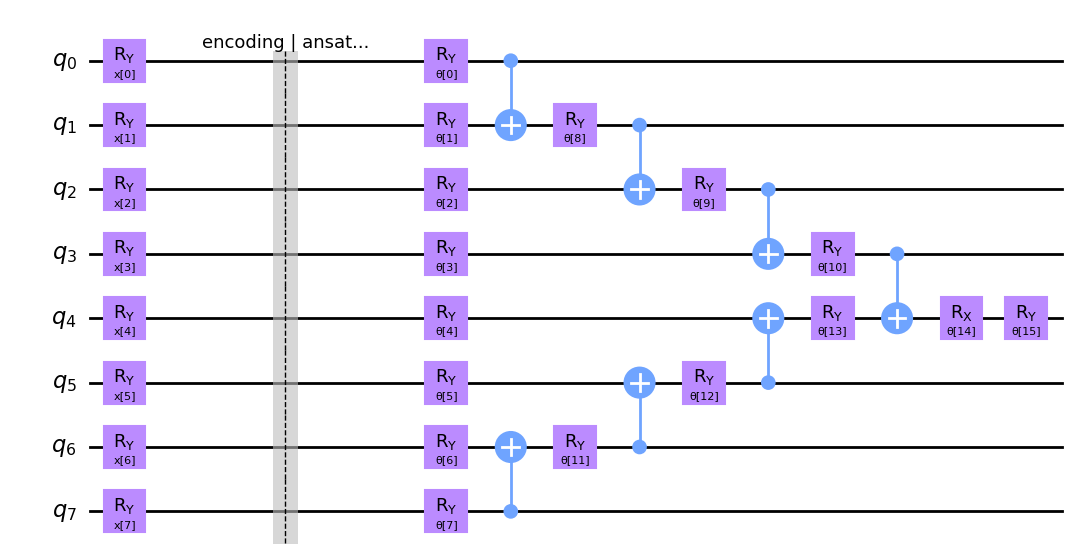

In [6]:
# An ansatz is a list of ops: ("rx"|"ry"|"rz", qubit) consumes the next parameter; ("cx", control, target) is fixed.
LEFT_CASCADE  = [(0, 1), (1, 2), (2, 3)]
RIGHT_CASCADE = [(7, 6), (6, 5), (5, 4)]
MERGE = (3, 4)
READOUT_QUBIT = 4

def manual_spec(blocks=1):
    ops = []
    for _ in range(blocks):
        ops += [("ry", q) for q in range(N_QUBITS)]
        for c, t in LEFT_CASCADE + RIGHT_CASCADE: ops += [("cx", c, t), ("ry", t)]
        ops += [("cx", *MERGE), ("rx", MERGE[1]), ("ry", MERGE[1])]
    return ops

def library_spec(kind, reps=2):            # mirrors qiskit's real_amplitudes / efficient_su2 (linear)
    ops = []
    for r in range(reps + 1):
        for q in range(N_QUBITS): ops.append(("ry", q))
        if kind == "su2":
            for q in range(N_QUBITS): ops.append(("rz", q))
        if r < reps: ops += [("cx", i, i + 1) for i in range(N_QUBITS - 1)]
    return ops

def product_spec():                    # NO entanglement: independent single-qubit rotations, 16 params
    return [(g, q) for g in ("ry", "rx") for q in range(N_QUBITS)]

def n_params(ops): return sum(o[0] != "cx" for o in ops)
def n_cx(ops): return sum(o[0] == "cx" for o in ops)

ALL_QUBITS = list(range(N_QUBITS))
DESIGNS = {   # name -> (ops, readout qubits)
    "manual (1 block)":      (manual_spec(1), [READOUT_QUBIT]),
    "manual (2 blocks)":     (manual_spec(2), [READOUT_QUBIT]),
    "manual (3 blocks)":     (manual_spec(3), [READOUT_QUBIT]),
    "real_amplitudes r2":    (library_spec("ra"), [7]),
    "efficient_su2 r2":      (library_spec("su2"), [7]),
    "product-state (no CNOT)": (product_spec(), ALL_QUBITS),
}

def build_circuit(ops):
    qc = QuantumCircuit(N_QUBITS); x = ParameterVector("x", N_QUBITS)
    for q in range(N_QUBITS): qc.ry(x[q], q)
    qc.barrier(label="encoding | ansatz")
    th = ParameterVector("θ", n_params(ops))   # "θ" sorts after "x": binding order is [x..., θ...]
    k = 0
    for o in ops:
        if o[0] == "cx": qc.cx(o[1], o[2])
        else: getattr(qc, o[0])(th[k], o[1]); k += 1
    assert [p.name for p in qc.parameters][:N_QUBITS] == [f"x[{i}]" for i in range(N_QUBITS)]
    return qc

def build_observable(readout):
    return SparsePauliOp.from_sparse_list([("Z", [q], 1.0 / len(readout)) for q in readout], num_qubits=N_QUBITS)

print(f"{'design':26s}{'params':>7s}{'CNOTs':>7s}{'param-shift runs / sample / step':>36s}")
for k, (ops, ro) in DESIGNS.items():
    print(f"{k:26s}{n_params(ops):7d}{n_cx(ops):7d}{2 * (n_params(ops) + N_QUBITS):36d}")
build_circuit(DESIGNS["manual (1 block)"][0]).draw("mpl", style="clifford", fold=-1)

## 4. Fast exact simulator, and proof that it equals Aer and the parameter-shift rule
A small batched PyTorch statevector simulator (8 qubits = 256 amplitudes). For ideal circuits whose trainable gates are `exp(-iθP/2)` used once, the shift-rule gradient is *identically* the analytic gradient, so `torch.autograd` through this simulator gives the same numbers as the 2-evaluations-per-parameter procedure — just ~1000x faster. Assertions below check that on this machine.

In [7]:
def _rot(kind, a):
    c, s = torch.cos(a / 2), torch.sin(a / 2); z = torch.zeros_like(c)
    if kind == "ry": return torch.stack([torch.stack([c, -s]), torch.stack([s, c])]).to(torch.complex128)
    if kind == "rx": return torch.stack([torch.stack([c + 0j, -1j * s]), torch.stack([-1j * s, c + 0j])])
    return torch.stack([torch.stack([torch.exp(-1j * a / 2), z + 0j]), torch.stack([z + 0j, torch.exp(1j * a / 2)])])

def _ax(q): return 1 + (N_QUBITS - 1 - q)            # Qiskit little-endian: qubit q <-> axis N-1-q

def _cx(psi, c, t):
    ac, at = _ax(c), _ax(t)
    idx = [slice(None)] * (N_QUBITS + 1); idx[ac] = 1
    sub = psi[tuple(idx)]; out = psi.clone()
    out[tuple(idx)] = torch.flip(sub, dims=[at - 1 if at > ac else at])
    return out

def sim_expectation(angles, theta, ops, readout):
    '''angles (B,8) float64, theta (P,) float64 -> mean <Z> over `readout` qubits, shape (B,). Differentiable.'''
    B = angles.shape[0]
    psi = torch.zeros((B,) + (2,) * N_QUBITS, dtype=torch.complex128); psi[(slice(None),) + (0,) * N_QUBITS] = 1
    for q in range(N_QUBITS):
        c, s = torch.cos(angles[:, q] / 2), torch.sin(angles[:, q] / 2)
        U = torch.stack([torch.stack([c, -s], -1), torch.stack([s, c], -1)], -2).to(torch.complex128)
        p = torch.movedim(psi, _ax(q), -1); p = torch.einsum("b...j,bij->b...i", p, U); psi = torch.movedim(p, -1, _ax(q))
    k = 0
    for o in ops:
        if o[0] == "cx": psi = _cx(psi, o[1], o[2])
        else:
            U = _rot(o[0], theta[k]); k += 1
            p = torch.movedim(psi, _ax(o[1]), -1) @ U.T; psi = torch.movedim(p, -1, _ax(o[1]))
    prob = psi.abs() ** 2; z = 0
    for q in readout:
        p0 = prob.movedim(_ax(q), 1).reshape(B, 2, -1).sum(-1); z = z + (p0[:, 0] - p0[:, 1])
    return z / len(readout)

# ---- equivalence checks on every design ----
rng = np.random.default_rng(0); est_chk = AerEstimator()
for name, (ops, ro) in DESIGNS.items():
    qc_, obs_ = build_circuit(ops), build_observable(ro); P = n_params(ops)
    A = rng.uniform(0.2, np.pi - 0.2, (3, N_QUBITS)); th = rng.uniform(0, 2 * np.pi, P)
    aer = np.array([r.data.evs for r in est_chk.run([(qc_, obs_, list(a) + list(th)) for a in A]).result()], float)
    mine = sim_expectation(torch.tensor(A), torch.tensor(th), ops, ro).numpy()
    t = torch.tensor(th, requires_grad=True); sim_expectation(torch.tensor(A), t, ops, ro).sum().backward()
    ps = []
    for j in range(P):
        tp, tm = th.copy(), th.copy(); tp[j] += SHIFT; tm[j] -= SHIFT
        ps.append((sim_expectation(torch.tensor(A), torch.tensor(tp), ops, ro) - sim_expectation(torch.tensor(A), torch.tensor(tm), ops, ro)).sum().item() / 2)
    e1, e2 = np.abs(aer - mine).max(), np.abs(np.array(ps) - t.grad.numpy()).max()
    print(f"{name:26s} |sim-Aer| = {e1:.1e}   |param-shift - autograd| = {e2:.1e}")
    assert e1 < 1e-9 and e2 < 1e-9

manual (1 block)           |sim-Aer| = 4.4e-16   |param-shift - autograd| = 6.4e-16
manual (2 blocks)          |sim-Aer| = 1.4e-16   |param-shift - autograd| = 6.7e-16
manual (3 blocks)          |sim-Aer| = 6.2e-17   |param-shift - autograd| = 5.0e-16
real_amplitudes r2         |sim-Aer| = 3.3e-16   |param-shift - autograd| = 7.1e-16
efficient_su2 r2           |sim-Aer| = 5.0e-16   |param-shift - autograd| = 5.3e-16
product-state (no CNOT)    |sim-Aer| = 5.6e-17   |param-shift - autograd| = 3.9e-16


## 5. Verifying the ansatz: light cone, dead parameters, barren-plateau check (§3.6 / Q10)
* **Light cone** — every encoded feature must influence the readout.
* **Dead parameters** — a parameter that never changes the output is wasted.
* **Gradient variance at initialisation** — variance across random initialisations; collapse towards 0 would be the barren-plateau signature. At 8 qubits it is expected to be healthy.

In [8]:
rng = np.random.default_rng(1)
Xp = torch.tensor(rng.uniform(0.2, np.pi - 0.2, (20, N_QUBITS)))
rows = []
for name, (ops, ro) in DESIGNS.items():
    P = n_params(ops)
    xx = Xp.clone().requires_grad_(True); th = torch.tensor(rng.uniform(0, 2 * np.pi, P))
    sim_expectation(xx, th, ops, ro).sum().backward(); lc = int((xx.grad.abs().sum(0) > 1e-9).sum())
    J = torch.autograd.functional.jacobian(lambda t: sim_expectation(Xp, t, ops, ro), th.clone().requires_grad_(True)).numpy()
    dead = int((np.abs(J).sum(0) < 1e-9).sum()); sv = np.linalg.svd(J, compute_uv=False); rank = int((sv > 1e-8 * sv[0]).sum())
    gs = []
    for _ in range(60):
        t = torch.tensor(rng.uniform(0, 2 * np.pi, P), requires_grad=True)
        sim_expectation(Xp, t, ops, ro).mean().backward(); gs.append(t.grad.numpy().copy())
    gv = np.array(gs).var(0)
    rows.append(dict(design=name, params=P, CNOTs=n_cx(ops), features_in_lightcone=f"{lc}/8", dead_params=dead,
                     effective_rank=f"{rank}/{P}", grad_var_mean=round(gv.mean(), 5), grad_var_min=round(gv.min(), 6)))
verif = pd.DataFrame(rows); display(verif)
print("Reading: gradient variance is non-vanishing for every design -> no barren-plateau signature at 8 qubits.")
print("effective_rank < params means some directions are redundant at that random point (information, not an error).")

,design,params,CNOTs,features_in_lightcone,dead_params,effective_rank,grad_var_mean,grad_var_min
0,manual (1 block),16,7,8/8,0,16/16,0.01664,0.000152
1,manual (2 blocks),32,14,8/8,0,20/32,0.00997,0.000140
2,manual (3 blocks),48,21,8/8,0,20/48,0.00631,0.000091
3,real_amplitudes r2,24,14,8/8,7,17/24,0.00715,0.000000
4,efficient_su2 r2,48,14,8/8,22,20/48,0.00235,0.000000
5,product-state (no CNOT),16,0,8/8,0,16/16,0.00209,0.001505


Reading: gradient variance is non-vanishing for every design -> no barren-plateau signature at 8 qubits.
effective_rank < params means some directions are redundant at that random point (information, not an error).


## 6. Hybrid training loop (Objective 4)
Adam updates the CNN weights **and** the ansatz parameters jointly; loss = binary cross-entropy on `p = (1 - <Z>)/2`; prediction = class 1 if `<Z> < 0`. Gradients flow back through the quantum layer exactly as the parameter-shift rule would deliver them (§4); the real shift-rule implementation is run in §7.

manual (1 block), seed 0: train acc 0.980 | test acc 0.785 | F1 0.796 | AUC 0.791 | 2.8s


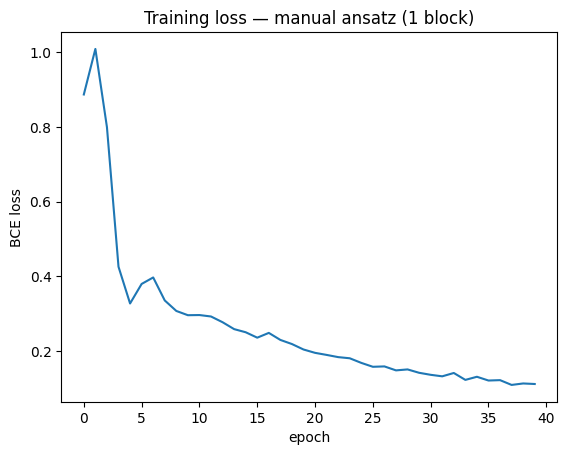

In [9]:
def metrics(y, z):
    pred = (np.asarray(z) < 0).astype(int)
    auc = roc_auc_score(y, -np.asarray(z)) if len(np.unique(y)) > 1 else float("nan")
    return dict(acc=accuracy_score(y, pred), f1=f1_score(y, pred), auc=auc)

def train_hybrid(ops, readout, split, seed, feature="cnn", epochs=None, lr=None, verbose=False):
    epochs = epochs or EPOCHS; lr = lr or LR
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    theta = nn.Parameter(torch.tensor(rng.uniform(0, 2 * np.pi, n_params(ops))))
    cnn = FeatureCNN() if feature == "cnn" else None
    opt = torch.optim.Adam(([theta] + list(cnn.parameters())) if cnn else [theta], lr=lr)
    ytr = torch.tensor(split["ytr"], dtype=torch.float64); hist = []
    for ep in range(epochs):
        if cnn: cnn.train()
        opt.zero_grad()
        ang = (np.pi * torch.sigmoid(cnn(split["img_tr"]))).double() if cnn else split["ang_tr"]
        z = sim_expectation(ang, theta, ops, readout)
        loss = F.binary_cross_entropy(((1 - z) / 2).clamp(1e-6, 1 - 1e-6), ytr); loss.backward(); opt.step()
        hist.append(loss.item())
        if verbose: print(f"epoch {ep + 1:3d} loss {loss.item():.4f}")
    if cnn: cnn.eval()
    with torch.no_grad():
        f = lambda img, a: (np.pi * torch.sigmoid(cnn(img))).double() if cnn else a
        ang_tr, ang_te = f(split["img_tr"], split["ang_tr"]), f(split["img_te"], split["ang_te"])
        z_tr = sim_expectation(ang_tr, theta, ops, readout).numpy(); z_te = sim_expectation(ang_te, theta, ops, readout).numpy()
        raw_tr = cnn(split["img_tr"]).numpy() if cnn else split["pca_tr"]; raw_te = cnn(split["img_te"]).numpy() if cnn else split["pca_te"]
    return dict(theta=theta.detach().numpy().copy(), cnn=cnn, hist=hist, z_te=z_te, ang_te=ang_te.numpy(),
                raw_tr=raw_tr, raw_te=raw_te, train=metrics(split["ytr"], z_tr), test=metrics(split["yte"], z_te))

t0 = time.time(); r = train_hybrid(*DESIGNS["manual (1 block)"], split0, seed=0, verbose=False)
print(f"manual (1 block), seed 0: train acc {r['train']['acc']:.3f} | test acc {r['test']['acc']:.3f} | F1 {r['test']['f1']:.3f} | AUC {r['test']['auc']:.3f} | {time.time() - t0:.1f}s")
plt.plot(r["hist"]); plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("Training loss — manual ansatz (1 block)"); plt.show()

## 7. The headline run with the *real* parameter-shift rule on Aer
The same procedure as the first-review notebooks (2 circuit evaluations per parameter, for the ansatz parameters **and** the 8 encoding angles, through a custom `torch.autograd.Function`), applied to the manual ansatz. The loss curve is then compared with the fast-simulator run on identical data/seed — they must coincide.

  [parameter-shift] epoch  1/12 loss 0.8164
  [parameter-shift] epoch  2/12 loss 0.6213
  [parameter-shift] epoch  3/12 loss 0.4415
  [parameter-shift] epoch  4/12 loss 0.3789
  [parameter-shift] epoch  5/12 loss 0.3387
  [parameter-shift] epoch  6/12 loss 0.2702
  [parameter-shift] epoch  7/12 loss 0.2386
  [parameter-shift] epoch  8/12 loss 0.2053
  [parameter-shift] epoch  9/12 loss 0.1922
  [parameter-shift] epoch 10/12 loss 0.1681
  [parameter-shift] epoch 11/12 loss 0.1302
  [parameter-shift] epoch 12/12 loss 0.1154
parameter-shift run: 100s | test acc 0.640 F1 0.719 AUC 0.818
max |loss(fast simulator) - loss(parameter-shift)| over 12 epochs = 1.41e-07


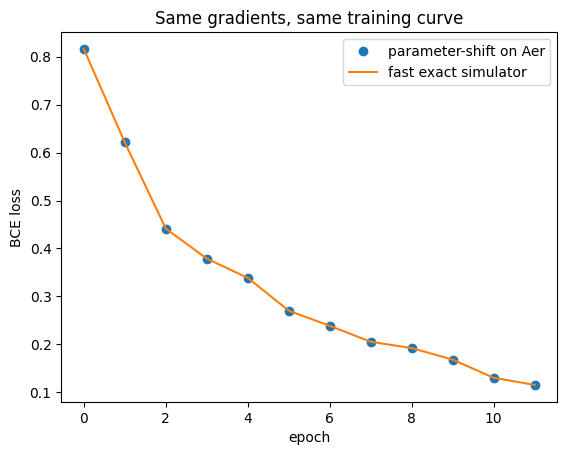

In [10]:
class PSCircuit:
    def __init__(self, ops, readout):
        self.ops, self.P = ops, n_params(ops); self.qc = build_circuit(ops); self.obs = build_observable(readout); self.est = AerEstimator()
    def expect(self, A, th):
        res = self.est.run([(self.qc, self.obs, list(a) + list(th)) for a in A]).result()
        return np.array([r.data.evs for r in res], dtype=np.float64)
    def backward(self, A, th, g):
        B = A.shape[0]; pubs = []
        for j in range(self.P):
            for s in (+SHIFT, -SHIFT):
                t2 = th.copy(); t2[j] += s; pubs += [(self.qc, self.obs, list(a) + list(t2)) for a in A]
        for i in range(N_QUBITS):
            for s in (+SHIFT, -SHIFT):
                for a in A:
                    a2 = a.copy(); a2[i] += s; pubs.append((self.qc, self.obs, list(a2) + list(th)))
        v = np.array([r.data.evs for r in self.est.run(pubs).result()], dtype=np.float64); k = 0
        gt = np.zeros(self.P); ga = np.zeros((B, N_QUBITS))
        for j in range(self.P):
            zp, zm = v[k:k + B], v[k + B:k + 2 * B]; k += 2 * B; gt[j] = np.sum(g * (zp - zm) / 2)
        for i in range(N_QUBITS):
            zp, zm = v[k:k + B], v[k + B:k + 2 * B]; k += 2 * B; ga[:, i] = g * (zp - zm) / 2
        return ga, gt

class QuantumExpectation(torch.autograd.Function):
    @staticmethod
    def forward(ctx, angles, theta, circ):
        ctx.circ, ctx.A, ctx.th = circ, angles.detach().numpy().astype(np.float64), theta.detach().numpy().astype(np.float64)
        return torch.tensor(circ.expect(ctx.A, ctx.th), dtype=torch.float32)
    @staticmethod
    def backward(ctx, go):
        ga, gt = ctx.circ.backward(ctx.A, ctx.th, go.detach().numpy().astype(np.float64))
        return torch.tensor(ga, dtype=torch.float32), torch.tensor(gt, dtype=torch.float32), None

def train_parameter_shift(ops, readout, split, seed, n_train, epochs, lr):
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    circ = PSCircuit(ops, readout)
    theta = nn.Parameter(torch.tensor(rng.uniform(0, 2 * np.pi, circ.P), dtype=torch.float32)); cnn = FeatureCNN()
    opt = torch.optim.Adam(list(cnn.parameters()) + [theta], lr=lr)
    img, y = split["img_tr"][:n_train], torch.tensor(split["ytr"][:n_train], dtype=torch.float32); hist = []
    for ep in range(epochs):
        cnn.train(); opt.zero_grad()
        z = QuantumExpectation.apply(np.pi * torch.sigmoid(cnn(img)), theta, circ)
        loss = F.binary_cross_entropy(((1 - z) / 2).clamp(1e-6, 1 - 1e-6), y); loss.backward(); opt.step(); hist.append(loss.item())
        print(f"  [parameter-shift] epoch {ep + 1:2d}/{epochs} loss {loss.item():.4f}")
    cnn.eval()
    with torch.no_grad(): ang_te = (np.pi * torch.sigmoid(cnn(split["img_te"]))).numpy().astype(np.float64)
    z_te = circ.expect(ang_te, theta.detach().numpy().astype(np.float64))
    return dict(hist=hist, test=metrics(split["yte"], z_te), cnn=cnn, theta=theta.detach().numpy().astype(np.float64), ang_te=ang_te, z_te=z_te)

ops1, ro1 = DESIGNS["manual (1 block)"]
t0 = time.time(); ps_run = train_parameter_shift(ops1, ro1, split0, 0, N_PS_TRAIN, N_PS_EPOCHS, 0.01)
print(f"parameter-shift run: {time.time() - t0:.0f}s | test acc {ps_run['test']['acc']:.3f} F1 {ps_run['test']['f1']:.3f} AUC {ps_run['test']['auc']:.3f}")

# same data / seed / config through the fast exact simulator
sub = {**split0, "img_tr": split0["img_tr"][:N_PS_TRAIN], "ytr": split0["ytr"][:N_PS_TRAIN]}
fast = train_hybrid(ops1, ro1, sub, 0, epochs=N_PS_EPOCHS, lr=0.01)
diff = np.max(np.abs(np.array(fast["hist"]) - np.array(ps_run["hist"])))
print(f"max |loss(fast simulator) - loss(parameter-shift)| over {N_PS_EPOCHS} epochs = {diff:.2e}")
assert diff < 5e-3, "fast simulator and parameter-shift training disagree"
plt.plot(ps_run["hist"], "o", label="parameter-shift on Aer"); plt.plot(fast["hist"], "-", label="fast exact simulator")
plt.legend(); plt.xlabel("epoch"); plt.ylabel("BCE loss"); plt.title("Same gradients, same training curve"); plt.show()

## 8. Multi-seed experiments (Section 8 success criteria, Q4, Q7)
Every row below is mean ± std over `SEEDS` (different balanced subsets, PCA fits, CNN inits and θ inits). With a few hundred images, differences smaller than about one std are **not** evidence of a real gap.

* **8a Ansatz comparison** — manual vs `real_amplitudes` vs `efficient_su2`.
* **8b Entanglement ablation** — manual (1 block) vs product-state circuit with no CNOTs (§3.2: no entanglement ⇒ equivalent to independent per-feature classical rotations).
* **8c Depth** — 1 / 2 / 3 manual blocks: accuracy vs stability vs cost.
* **8d Features** — trainable CNN vs plain PCA (Q4).

In [11]:
def run_grid(names, feature="cnn", lr=None):
    out = []
    for name in names:
        ops, ro = DESIGNS[name]
        for s in SEEDS:
            sp = SPLITS[s]; t0 = time.time(); r = train_hybrid(ops, ro, sp, s, feature=feature, lr=lr)
            out.append(dict(design=name, feature=feature, seed=s, params=n_params(ops), cnots=n_cx(ops),
                            train_acc=r["train"]["acc"], acc=r["test"]["acc"], f1=r["test"]["f1"], auc=r["test"]["auc"],
                            final_loss=r["hist"][-1], secs=time.time() - t0))
            RUNS[(name, feature, s)] = r
        print("done", name, feature, flush=True)
    return pd.DataFrame(out)

SPLITS = {s: make_split(s) for s in SEEDS}; RUNS = {}
def summarize(df, by=("design", "feature")):
    g = df.groupby(list(by), sort=False)
    t = g.agg(params=("params", "first"), cnots=("cnots", "first"), acc_mean=("acc", "mean"), acc_std=("acc", "std"),
              f1_mean=("f1", "mean"), f1_std=("f1", "std"), auc_mean=("auc", "mean"), train_acc=("train_acc", "mean"), secs=("secs", "mean"))
    return t.round(3)

In [12]:
# 8a + 8b + 8c in one pass (all with the trainable CNN features)
df_main = run_grid(list(DESIGNS.keys()), feature="cnn")
res_main = summarize(df_main); display(res_main)

done manual (1 block) cnn
done manual (2 blocks) cnn
done manual (3 blocks) cnn
done real_amplitudes r2 cnn
done efficient_su2 r2 cnn
done product-state (no CNOT) cnn


,,params,cnots,acc_mean,acc_std,f1_mean,f1_std,auc_mean,train_acc,secs
design,feature,,,,,,,,,
manual (1 block),cnn,16,7,0.800,0.022,0.813,0.021,0.865,0.980,3.018
manual (2 blocks),cnn,32,14,0.788,0.044,0.809,0.033,0.864,0.981,4.850
manual (3 blocks),cnn,48,21,0.803,0.031,0.817,0.026,0.864,0.979,6.644
real_amplitudes r2,cnn,24,14,0.817,0.032,0.827,0.028,0.871,0.968,3.894
efficient_su2 r2,cnn,48,14,0.811,0.052,0.825,0.036,0.864,0.976,6.272
product-state (no CNOT),cnn,16,0,0.802,0.025,0.818,0.021,0.871,0.978,2.783


In [13]:
# 8d: PCA features without the CNN (documented ablation, Q4) for the main manual design and the two library ansätze
df_pca = run_grid(["manual (1 block)", "real_amplitudes r2", "efficient_su2 r2"], feature="pca", lr=0.1)
display(summarize(df_pca))

done manual (1 block) pca
done real_amplitudes r2 pca
done efficient_su2 r2 pca


,,params,cnots,acc_mean,acc_std,f1_mean,f1_std,auc_mean,train_acc,secs
design,feature,,,,,,,,,
manual (1 block),pca,16,7,0.726,0.098,0.762,0.069,0.825,0.807,2.022
real_amplitudes r2,pca,24,14,0.799,0.060,0.813,0.043,0.888,0.831,3.299
efficient_su2 r2,pca,48,14,0.839,0.023,0.840,0.021,0.920,0.845,5.372


## 9. Classical baselines (Objective 5, Q3)
Per the study guide the comparison must be **apples to apples**:
1. **SVM (RBF) on the same learned CNN features** of each quantum run;
2. **Shallow MLP (8 hidden units) on the same features**;
3. **Classical twin**: the identical CNN, with the quantum layer replaced by a single linear unit, trained with the same optimiser/epochs;
4. **Raw-pixel SVM** (784 standardised pixels) and **PCA-8 SVM** — "is any of this adding anything over plain compression?" (Q3).

In [14]:
def train_classical_twin(split, seed):
    torch.manual_seed(seed); cnn = FeatureCNN(); head = nn.Linear(N_QUBITS, 1)
    opt = torch.optim.Adam(list(cnn.parameters()) + list(head.parameters()), lr=LR); y = torch.tensor(split["ytr"], dtype=torch.float32)
    for _ in range(EPOCHS):
        cnn.train(); opt.zero_grad(); loss = F.binary_cross_entropy_with_logits(head(cnn(split["img_tr"])).squeeze(1), y); loss.backward(); opt.step()
    cnn.eval()
    with torch.no_grad(): logit = head(cnn(split["img_te"])).squeeze(1).numpy()
    return metrics(split["yte"], -logit)                      # z<0 <=> logit>0 <=> class 1

rows = []
for s in SEEDS:
    sp = SPLITS[s]
    def add(name, pred, score):
        rows.append(dict(model=name, seed=s, acc=accuracy_score(sp["yte"], pred), f1=f1_score(sp["yte"], pred), auc=roc_auc_score(sp["yte"], score)))
    r = RUNS[("manual (1 block)", "cnn", s)]
    sc = StandardScaler().fit(r["raw_tr"]); ftr, fte = sc.transform(r["raw_tr"]), sc.transform(r["raw_te"])
    svm = SVC(kernel="rbf", random_state=s).fit(ftr, sp["ytr"]); add("SVM on the manual run's CNN features", svm.predict(fte), svm.decision_function(fte))
    mlp = MLPClassifier((8,), max_iter=2000, random_state=s).fit(ftr, sp["ytr"]); add("Shallow MLP on the same features", mlp.predict(fte), mlp.predict_proba(fte)[:, 1])
    tw = train_classical_twin(sp, s); rows.append(dict(model="Classical twin (same CNN + linear head)", seed=s, **tw))
    sc2 = StandardScaler().fit(sp["pca_tr"]); p_tr, p_te = sc2.transform(sp["pca_tr"]), sc2.transform(sp["pca_te"])
    m = SVC(kernel="rbf", random_state=s).fit(p_tr, sp["ytr"]); add("SVM on PCA-8 features", m.predict(p_te), m.decision_function(p_te))
    sc3 = StandardScaler().fit(sp["pix_tr"]); q_tr, q_te = sc3.transform(sp["pix_tr"]), sc3.transform(sp["pix_te"])
    m = SVC(kernel="rbf", random_state=s).fit(q_tr, sp["ytr"]); add("SVM on raw pixels (784)", m.predict(q_te), m.decision_function(q_te))
df_cls = pd.DataFrame(rows)
res_cls = df_cls.groupby("model", sort=False).agg(acc_mean=("acc", "mean"), acc_std=("acc", "std"), f1_mean=("f1", "mean"), auc_mean=("auc", "mean")).round(3)
display(res_cls)

,acc_mean,acc_std,f1_mean,auc_mean
model,,,,
SVM on the manual run's CNN features,0.790,0.027,0.808,0.880
Shallow MLP on the same features,0.779,0.018,0.799,0.854
Classical twin (same CNN + linear head),0.778,0.043,0.803,0.880
SVM on PCA-8 features,0.808,0.030,0.822,0.897
SVM on raw pixels (784),0.841,0.011,0.855,0.932


## 10. NISQ noise (§3.5, Q9)
**10a Shots** — how many shots does the readout need? (ideal circuit, only shot noise.)
**10b FakeSherbrooke** — the trained manual / `real_amplitudes` / `efficient_su2` models (seed 0) evaluated on the noisy simulator, with the transpiled two-qubit-gate count and depth. This is the preview of the real-hardware gap; the earlier notebooks' two built-in runs collapsed to 0.500 here.

In [15]:
sd = SEEDS[0]; sp = SPLITS[sd]
sel = np.arange(min(N_NOISY, len(sp["yte"])))                 # first N_NOISY test images (balanced subset is shuffled)
y_sel = sp["yte"][sel]
# ---- 10a shots ----
name = "manual (1 block)"; ops, ro = DESIGNS[name]; r = RUNS[(name, "cnn", sd)]
qc_m, obs_m = build_circuit(ops), build_observable(ro); rows = []
for shots in SHOTS_LIST:
    e = AerEstimator()
    z = np.array([x.data.evs for x in e.run(
            [(qc_m, obs_m, list(a) + list(r["theta"])) for a in r["ang_te"][sel]],
            precision=1/np.sqrt(shots)).result()])
    rows.append(dict(shots=shots, acc=metrics(y_sel, z)["acc"], mean_abs_dev_from_exact=np.abs(z - r["z_te"][sel]).mean()))
display(pd.DataFrame(rows).round(4))

,shots,acc,mean_abs_dev_from_exact
0,100,0.850,0.0758
1,500,0.825,0.0368
2,1000,0.825,0.0210
3,4000,0.825,0.0114
4,8000,0.825,0.0080


In [16]:
# ---- 10b FakeSherbrooke ----
backend = FakeSherbrooke(); noisy_sim = AerSimulator.from_backend(backend)
rows = []; NOISY_Z = {}
for name in ["manual (1 block)", "real_amplitudes r2", "efficient_su2 r2"]:
    ops, ro = DESIGNS[name]; r = RUNS[(name, "cnn", sd)]
    qc_, obs_ = build_circuit(ops), build_observable(ro)
    tq = transpile(qc_, noisy_sim, optimization_level=1, seed_transpiler=1); ob_t = obs_.apply_layout(tq.layout)
    est = AerEstimator.from_backend(noisy_sim);
    z_noisy = np.array([x.data.evs for x in est.run(
            [(tq, ob_t, list(a) + list(r["theta"])) for a in r["ang_te"][sel]],
            precision=1/np.sqrt(SHOTS_NOISY)).result()])
    NOISY_Z[name] = z_noisy
    ideal = metrics(y_sel, r["z_te"][sel]); noisy = metrics(y_sel, z_noisy)
    ops_count = tq.count_ops()
    rows.append(dict(design=name, ideal_acc=ideal["acc"], noisy_acc=noisy["acc"], gap=ideal["acc"] - noisy["acc"], noisy_f1=noisy["f1"],
                     two_qubit_gates=ops_count.get("ecr", 0) + ops_count.get("cx", 0), depth=tq.depth(), two_qubit_depth=tq.depth(lambda i: i.operation.num_qubits == 2)))
df_noise = pd.DataFrame(rows).round(3); display(df_noise)
print("A positive ideal-vs-noisy gap is the expected, reportable NISQ result (§3.5) — not a failure.")

,design,ideal_acc,noisy_acc,gap,noisy_f1,two_qubit_gates,depth,two_qubit_depth
0,manual (1 block),0.825,0.825,0.000,0.863,7,35,4
1,real_amplitudes r2,0.850,0.525,0.325,0.558,14,45,9
2,efficient_su2 r2,0.825,0.675,0.150,0.772,14,52,9


A positive ideal-vs-noisy gap is the expected, reportable NISQ result (§3.5) — not a failure.


## 11. Optional: real IBM Quantum hardware (Week 4, Q5)
Disabled by default. To run it: create a free IBM Quantum account, copy your API key into `IBM_TOKEN`, set `RUN_HARDWARE = True`. It sends only `N_HARDWARE` test images for the manual model (one `EstimatorV2` job), staying inside the free ~10 minutes. If access is delayed, §10b is the fallback described in the study guide — nothing else depends on this section.
> ⚠ This cell uses the IBM Runtime API; I could not execute it from my sandbox (no account/network), so treat it as untested until your first run. The channel/instance arguments may need adjusting to your account.

In [17]:
hw_result = None
if RUN_HARDWARE:
    from qiskit_ibm_runtime import QiskitRuntimeService, EstimatorV2 as RuntimeEstimator
    from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
    service = QiskitRuntimeService(channel="ibm_quantum_platform", token=IBM_TOKEN)
    hw_backend = service.least_busy(operational=True, simulator=False, min_num_qubits=N_QUBITS)
    print("using", hw_backend.name)
    name = "manual (1 block)"; ops, ro = DESIGNS[name]; r = RUNS[(name, "cnn", sd)]
    pm = generate_preset_pass_manager(optimization_level=1, backend=hw_backend)
    isa = pm.run(build_circuit(ops)); isa_obs = build_observable(ro).apply_layout(isa.layout)
    hsel = sel[:N_HARDWARE]
    est = RuntimeEstimator(mode=hw_backend); est.options.default_shots = SHOTS_NOISY
    job = est.run([(isa, isa_obs, [list(a) + list(r["theta"]) for a in r["ang_te"][hsel]])])
    z_hw = np.array(job.result()[0].data.evs).reshape(-1)
    hw_result = dict(backend=hw_backend.name, ideal=metrics(sp["yte"][hsel], r["z_te"][hsel]), hardware=metrics(sp["yte"][hsel], z_hw))
    print(hw_result)
else:
    print("RUN_HARDWARE=False -> skipped (FakeSherbrooke in §10b is the simulator-only fallback).")

qiskit_runtime_service._discover_account:WARNING:2026-10-13 14:38:23,488: Loading account with the given token. A saved account will not be used.
qiskit_runtime_service.__init__:WARNING:2026-10-13 14:38:26,684: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.backends:WARNING:2026-10-13 14:38:27,205: Loading instance: open-instance, plan: open
qiskit_runtime_service.backends:WARNING:2026-10-13 14:38:29,838: Using instance: open-instance, plan: open


using ibm_marrakesh
{'backend': 'ibm_marrakesh', 'ideal': {'acc': 0.9, 'f1': 0.9090909090909091, 'auc': np.float64(0.93)}, 'hardware': {'acc': 0.9, 'f1': 0.9090909090909091, 'auc': np.float64(0.9500000000000001)}}


## 12. Benchmark summary, figures and auto-generated results text (Objective 5, §8)

,model,acc,acc_std,f1,auc,params,cnots
0,HVQC — manual (1 block),0.800,0.022,0.813,0.865,16.0,7.0
1,HVQC — manual (2 blocks),0.788,0.044,0.809,0.864,32.0,14.0
2,HVQC — manual (3 blocks),0.803,0.031,0.817,0.864,48.0,21.0
3,HVQC — real_amplitudes r2,0.817,0.032,0.827,0.871,24.0,14.0
4,HVQC — efficient_su2 r2,0.811,0.052,0.825,0.864,48.0,14.0
5,HVQC — product-state (no CNOT),0.802,0.025,0.818,0.871,16.0,0.0
6,Classical — SVM on the manual run's CNN features,0.790,0.027,0.808,0.880,NaN,NaN
7,Classical — Shallow MLP on the same features,0.779,0.018,0.799,0.854,NaN,NaN
8,Classical — Classical twin (same CNN + linear ...,0.778,0.043,0.803,0.880,NaN,NaN
9,Classical — SVM on PCA-8 features,0.808,0.030,0.822,0.897,NaN,NaN


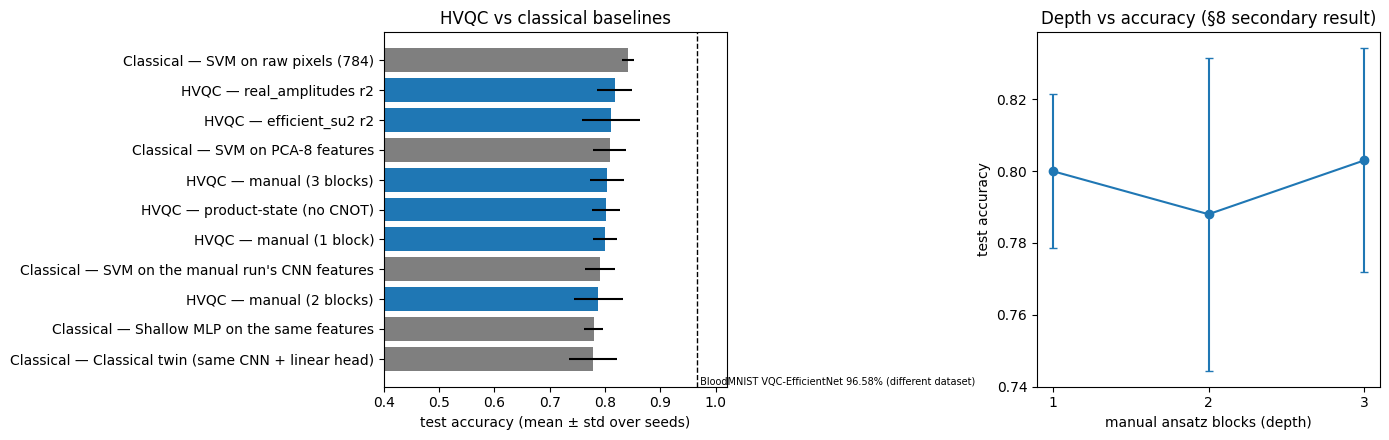

In [18]:
rows = []
for name, g in df_main.groupby("design", sort=False):
    rows.append((f"HVQC — {name}", g.acc.mean(), g.acc.std(), g.f1.mean(), g.auc.mean(), int(g.params.iloc[0]), int(g.cnots.iloc[0])))
for name, g in df_cls.groupby("model", sort=False):
    rows.append((f"Classical — {name}", g.acc.mean(), g.acc.std(), g.f1.mean(), g.auc.mean(), None, None))
summary = pd.DataFrame(rows, columns=["model", "acc", "acc_std", "f1", "auc", "params", "cnots"]).round(3)
display(summary)
summary.to_csv("hvqc_results_summary.csv", index=False); df_main.to_csv("hvqc_runs_main.csv", index=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
m = summary.sort_values("acc"); colors = ["tab:blue" if s.startswith("HVQC") else "tab:gray" for s in m.model]
ax[0].barh(m.model, m.acc, xerr=m.acc_std.fillna(0), color=colors); ax[0].axvline(0.9658, ls="--", c="k", lw=1)
ax[0].text(0.9658, -0.6, " BloodMNIST VQC-EfficientNet 96.58% (different dataset)", fontsize=7, va="top")
ax[0].set_xlabel("test accuracy (mean ± std over seeds)"); ax[0].set_title("HVQC vs classical baselines"); ax[0].set_xlim(0.4, 1.02)
dep = df_main[df_main.design.str.startswith("manual")].groupby("design", sort=False).acc.agg(["mean", "std"]);
ax[1].errorbar([1, 2, 3], dep["mean"], yerr=dep["std"].fillna(0), marker="o", capsize=3); ax[1].set_xticks([1, 2, 3])
ax[1].set_xlabel("manual ansatz blocks (depth)"); ax[1].set_ylabel("test accuracy"); ax[1].set_title("Depth vs accuracy (§8 secondary result)")
plt.tight_layout(); plt.savefig("hvqc_results.png", dpi=150); plt.show()

In [19]:
best_q = df_main.groupby("design").acc.mean().idxmax(); man = df_main[df_main.design == "manual (1 block)"]
lib = df_main[df_main.design.isin(["real_amplitudes r2", "efficient_su2 r2"])]; prod = df_main[df_main.design == "product-state (no CNOT)"]
g = lambda d: f"{d.acc.mean():.3f} ± {d.acc.std():.3f}"
txt = f'''RESULTS (auto-generated; {len(SEEDS)} seeds, N_TRAIN={N_TRAIN}, N_TEST={N_TEST}, PneumoniaMNIST 28x28, 8 qubits)

* Manual 1-block ansatz (16 params, 7 CNOTs): test accuracy {g(man)}, F1 {man.f1.mean():.3f}, AUC {man.auc.mean():.3f}.
* Library ansätze: real_amplitudes {g(df_main[df_main.design == 'real_amplitudes r2'])} (24 params, 14 CNOTs); efficient_su2 {g(df_main[df_main.design == 'efficient_su2 r2'])} (48 params, 14 CNOTs).
* Entanglement ablation: product-state circuit without CNOTs {g(prod)} vs manual {g(man)}.
* Best configuration by mean accuracy: {best_q}.
* Classical controls (same data): {', '.join(f"{k} {v:.3f}" for k, v in res_cls.acc_mean.items())}.
* FakeSherbrooke (seed {sd}, {len(sel)} test images): ''' + '; '.join(f"{r.design}: ideal {r.ideal_acc:.3f} -> noisy {r.noisy_acc:.3f} ({int(r.two_qubit_gates)} two-qubit gates)" for r in df_noise.itertuples()) + f'''.
* Hardware: {hw_result if hw_result else "not run"}.

HOW TO READ IT: if differences are smaller than ~1 std they are not evidence of a gap. The study guide's success criterion is comparability with auto-generated-ansatz work plus interpretability, not beating it; BloodMNIST (96.58%) is a different dataset and sample size, so it is context, not a like-for-like target.'''
print(txt); open("hvqc_results.txt", "w").write(txt)

RESULTS (auto-generated; 5 seeds, N_TRAIN=200, N_TEST=200, PneumoniaMNIST 28x28, 8 qubits)

* Manual 1-block ansatz (16 params, 7 CNOTs): test accuracy 0.800 ± 0.022, F1 0.813, AUC 0.865.
* Library ansätze: real_amplitudes 0.817 ± 0.032 (24 params, 14 CNOTs); efficient_su2 0.811 ± 0.052 (48 params, 14 CNOTs).
* Entanglement ablation: product-state circuit without CNOTs 0.802 ± 0.025 vs manual 0.800 ± 0.022.
* Best configuration by mean accuracy: real_amplitudes r2.
* Classical controls (same data): SVM on the manual run's CNN features 0.790, Shallow MLP on the same features 0.779, Classical twin (same CNN + linear head) 0.778, SVM on PCA-8 features 0.808, SVM on raw pixels (784) 0.841.
* FakeSherbrooke (seed 0, 40 test images): manual (1 block): ideal 0.825 -> noisy 0.825 (7 two-qubit gates); real_amplitudes r2: ideal 0.850 -> noisy 0.525 (14 two-qubit gates); efficient_su2 r2: ideal 0.825 -> noisy 0.675 (14 two-qubit gates).
* Hardware: {'backend': 'ibm_marrakesh', 'ideal': {'acc': 0.

1464

## 13. What to say about it (reviewer checklist)
* **Research question** (§1) answered by §8a/8b (is a transparent circuit competitive?) and §9 (does the quantum layer add anything over the same features?).
* **Entanglement matters?** §8b — compare manual vs product-state.
* **Depth trade-off** (§8 secondary) — §8c table + figure.
* **Barren plateaus** (Q10) — §5 gradient variance, measured not assumed.
* **NISQ gap** (§3.5, Q5) — §10b (and §11 if run).
* **Shots** (Q9) — §10a gives the measured answer for your chosen shot count.
* **Honest limits:** small subsets, tiny differences within seed noise, simulator results, the hardware cell untested until your first run, and the CNN (25.8k parameters) does most of the classical work — read §9's classical twin before claiming a quantum benefit.